In [16]:
#this is so that the import work correctly
#put here the directory to your folder
import sys  
sys.path.insert(1, '/Users/qwpie/OneDrive/Bureaublad/programming & data analysis/Free-project-simulation')

import importlib


import numpy as np
from constants_folder.constants import *
from calculate_functions.calculation_acc_alpha import calculating_acceleration_and_alpha
from calculate_functions.calculation_energy_velocity_cm import calculating_energy, calculate_velocity_center_of_mass
from calculate_functions.calculation_moment_of_inertia import calucate_moment_of_inertia
from calculate_functions.calculation_mass_offset import calculating_offset_1

importlib.reload(sys.modules['calculate_functions.calculation_moment_of_inertia'])
importlib.reload(sys.modules['constants_folder.constants'])
importlib.reload(sys.modules['calculate_functions.calculation_mass_offset'])
importlib.reload(sys.modules['calculate_functions.calculation_energy_velocity_cm'])
importlib.reload(sys.modules['calculate_functions.calculation_acc_alpha'])

'''
assumptions:
friction direction is always negative x
the ball rolls smooth
'''
#setting the offset and moment of inertia
OFFSET_1 = calculating_offset_1(OFFSET_2, MASS, RADIUS_CILINDER, RADIUS_HOLE, ADDED_MASS)               #[m]
#OFFSET_1 = 0.125

I = calucate_moment_of_inertia(MASS, RADIUS_CILINDER, RADIUS_HOLE, OFFSET_1, OFFSET_2, ADDED_MASS)      #[kg m^2]
print(LENGHT)


#creating dictionaries
time_dic = {}
position_dic = {}
velocity_dic = {}
acceleration_dic = {}
angle_dic = {}
angular_velocity_dic = {}
angular_acceleration_dic = {}
total_energy_dic = {}
height_dic = {}
velocity_center_of_mass_dic = {}
kinetic_energy_dic = {}
potential_energy_dic = {}

#giving initial values to there variables
x, phi, v, omega, t = x0, phi0, v0, omega0, t0

#if the offset is 0 the center of mass can't have a angle, so it's 0. this way the gravitational force doesn't exert torque
if OFFSET_1 > 0:
    a, alpha = calculating_acceleration_and_alpha(I, MASS, RADIUS_CILINDER, phi, ANGLE_SLOPE[0], omega, OFFSET_1, RADIUS_HOLE, ADDED_MASS)

else:
    a, alpha = calculating_acceleration_and_alpha(I, MASS, RADIUS_CILINDER, 0, ANGLE_SLOPE[0], omega, OFFSET_1, RADIUS_HOLE, ADDED_MASS)

#calculating begin energy
energy, h, e_k, e_p = calculating_energy(I, v, MASS, omega, RADIUS_CILINDER, RADIUS_HOLE, ANGLE_SLOPE[0], x, phi, OFFSET_1, ADDED_MASS)

#creating lists to add values of the variables to later
position = [x0]
velocity = [v0]
angle = [phi0]
angular_velocity = [omega0]
time = [t0]
acceleration = [a]
angular_acceleration = [alpha]
total_energy = [energy]
end_times = []
height = [h]
velocity_center_of_mass = [v_cm0]
kinetic_energy = [e_k]
potential_energy = [e_p]

#for loop so that every slope angle has an calculation. f is to keep track of the how many times de loop has gone.
for theta, f in zip(ANGLE_SLOPE, range(len(ANGLE_SLOPE))):

    #reastablising the variables as there begin values for ANGLE_SLOPE 2, 3 ect. 
    x, phi, v, omega, t, v_cm = x0, phi0, v0, omega0, t0, v_cm0

    # while loop in which the simulation takes place
    while True:
    
        #updating the variables every loop

        #if the offset is 0 the center of mass can't have a angle, so it's 0. this way the gravitational force doesn't exert torque
        if OFFSET_1 > 0:
            a, alpha = calculating_acceleration_and_alpha(I, MASS, RADIUS_CILINDER, phi, theta, omega, OFFSET_1, RADIUS_HOLE, ADDED_MASS)

        else:
            a, alpha = calculating_acceleration_and_alpha(I, MASS, RADIUS_CILINDER, 0, theta, omega, OFFSET_1, RADIUS_HOLE, ADDED_MASS)

        
        v = v + a * dt
        v_cm = calculate_velocity_center_of_mass(phi, v, omega, OFFSET_1)

        omega = omega + alpha * dt
        x = x + v * dt

        #you divide by 2 pi and take the remainder, because its easier to understand in the plot
        phi = phi + omega * dt
        t = t + dt

        engery, h, e_k, e_p = calculating_energy(I, v, MASS, omega, RADIUS_CILINDER, RADIUS_HOLE, theta, x, phi, OFFSET_1, ADDED_MASS)

        #adding the variables to their lists
        position.append(x)
        velocity.append(v)
        angle.append(phi)
        angular_velocity.append(omega)
        time.append(t)
        acceleration.append(a)
        angular_acceleration.append(alpha)
        total_energy.append(engery)
        height.append(h)
        velocity_center_of_mass.append(v_cm)
        kinetic_energy.append(e_k)
        potential_energy.append(e_p)
        
        #condition to end the while loop. It's when the ball has gone further than the length of the planck
        if x >= LENGHT or t >= end_time:

            #adding every list to a dictionary under a diffrent name
            time_dic['time_{0}'.format(f)] = time
            velocity_dic['velocity_{0}'.format(f)] = velocity
            position_dic['position_{0}'.format(f)] = position
            acceleration_dic['acceleration_{0}'.format(f)] = acceleration
            angle_dic['angle_{0}'.format(f)] = angle
            angular_velocity_dic['angular_velocity_{0}'.format(f)] = angular_velocity
            angular_acceleration_dic['angular_acceleration_{0}'.format(f)] = angular_acceleration
            total_energy_dic['total_energy_{0}'.format(f)] = total_energy
            end_times.append(time[-1])
            height_dic['height_{0}'.format(f)] = height
            velocity_center_of_mass_dic['velocity_center_of_mass_{0}'.format(f)] = velocity_center_of_mass
            kinetic_energy_dic['kinetic_energy_{0}'.format(f)] = kinetic_energy
            potential_energy_dic['potential_energy_{0}'.format(f)] = potential_energy

            #preperation for next simulation
            #to delete the old list so that is doesn't contain the values of the first simulation anymore
            #f + 1, because we still are in the old simulation loop, but you already want de values for the new simulation
            if f != len(ANGLE_SLOPE) - 1:

                a, alpha = calculating_acceleration_and_alpha(I, MASS, RADIUS_CILINDER, phi0, ANGLE_SLOPE[(f + 1)], omega, OFFSET_1, RADIUS_HOLE, ADDED_MASS)
                energy, h, e_k, e_p = calculating_energy(I, v0, MASS, omega0, RADIUS_CILINDER, RADIUS_HOLE, ANGLE_SLOPE[(f + 1)], x0, phi0, OFFSET_1, ADDED_MASS)


                position = [x0]
                velocity = [v0]
                angle = [phi0]
                angular_velocity = [omega0]
                time = [t0]
                acceleration = [a]
                angular_acceleration = [alpha]
                total_energy = [energy]
                height = [h]
                velocity_center_of_mass = [v_cm0]
                kinetic_energy = [e_k]
                potential_energy = [e_p]
  
            break
print(end_times)

30.0
20.0
[3.9056000000038176, 3.279900000002497, 2.917800000001733, 2.688400000001249, 2.539700000000935]


<>:119: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:119: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
C:\Users\qwpie\AppData\Local\Temp\ipykernel_6904\315032592.py:119: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  ax3.yaxis.set_major_formatter(tck.FormatStrFormatter('%g $\pi$'))


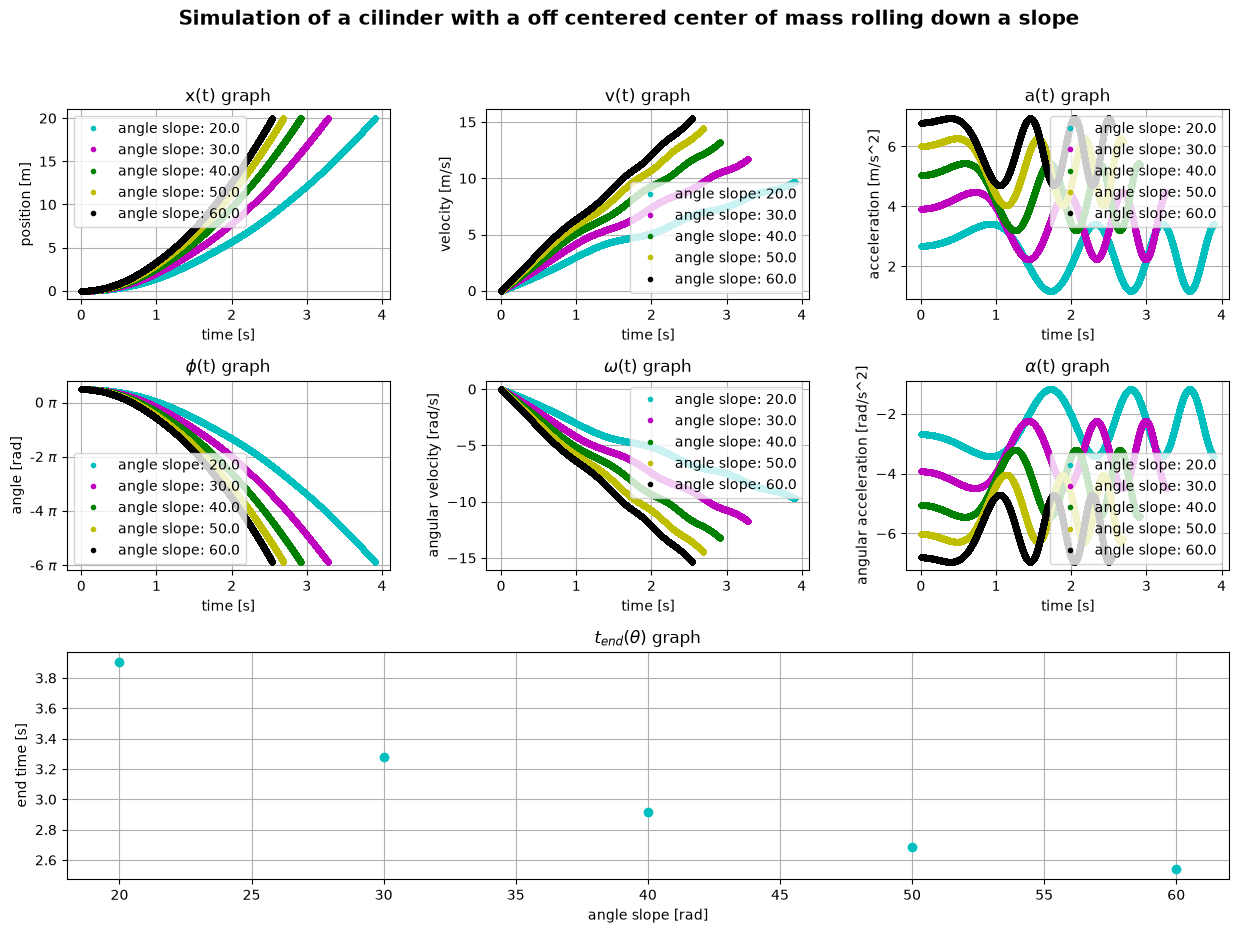

With a slope with angle : 20 degrees, the end time is: 3.9056 seconds
With a slope with angle : 30 degrees, the end time is: 3.2799 seconds
With a slope with angle : 40 degrees, the end time is: 2.9178 seconds
With a slope with angle : 50 degrees, the end time is: 2.6884 seconds
With a slope with angle : 60 degrees, the end time is: 2.5397 seconds


In [17]:
import matplotlib.pyplot as plt
import matplotlib.ticker as tck

rows = 3
colomns = 3

#creating a enviorment for the plots
fig = plt.figure(figsize=(15, 10))
gs = fig.add_gridspec(rows, colomns, height_ratios=[1, 1, 1.2], hspace=0.4, wspace=0.3)

# create  4 subplots in a 2x2 square
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])
ax6 = fig.add_subplot(gs[0, 2])
ax7 = fig.add_subplot(gs[1, 2])

# create a 5th big subplot allong the bottom
ax5 = fig.add_subplot(gs[2, :])

#for loop to plot all the simulations
for an_value, p_value, v_value, ac_value, an_v_value, an_ac_value, t_value, i in zip(angle_dic.values(), position_dic.values(), velocity_dic.values(), acceleration_dic.values(), angular_velocity_dic.values(), angular_acceleration_dic.values(), time_dic.values(), range(len(ANGLE_SLOPE))):

    an_value_new = []
    
    #to get the simulations for the diffrent angles a diffrent color.
    if i%6 == 0:
        color_dot = 'c.' 
    elif i%6 == 1:
        color_dot = 'm.'
    elif i%6 == 2:
        color_dot = 'g.'
    elif i%6 == 3:
         color_dot = 'y.'
    elif i%6 == 4:
        color_dot = 'k.'
    else:
        color_dot = 'b.'

    #calculating the angels in pi so it is easier to understand
    for an in an_value:
        an_value_new.append(an / np.pi)

    #plotting all the simulations
    ax2.plot(t_value, v_value, color_dot, label= f'angle slope: {np.rad2deg(ANGLE_SLOPE[i]):.1f}')
    ax6.plot(t_value, ac_value, color_dot, label= f'angle slope: {np.rad2deg(ANGLE_SLOPE[i]):.1f}')
    ax4.plot(t_value, an_v_value, color_dot, label= f'angle slope: {np.rad2deg(ANGLE_SLOPE[i]):.1f}')
    ax7.plot(t_value, an_ac_value, color_dot, label= f'angle slope: {np.rad2deg(ANGLE_SLOPE[i]):.1f}')
    ax1.plot(t_value, p_value, color_dot, label= f'angle slope: {np.rad2deg(ANGLE_SLOPE[i]):.1f}')
    ax3.plot(t_value, an_value_new, color_dot, label= f'angle slope: {np.rad2deg(ANGLE_SLOPE[i]):.1f}')

#plotting end time against angle slope
ax5.plot(np.rad2deg(ANGLE_SLOPE), end_times, 'co')

#setting x/y labels to the plots

ax2.set(
    xlabel= 'time [s]',
    ylabel = 'velocity [m/s]',
    title = 'v(t) graph'
)

ax6.set(
    xlabel= 'time [s]',
    ylabel = 'acceleration [m/s^2]',
    title = 'a(t) graph'
)

ax4.set(
    xlabel= 'time [s]',
    ylabel = 'angular velocity [rad/s]',
    title = r'$\omega$(t) graph'
)

ax7.set(
    xlabel= 'time [s]',
    ylabel = 'angular acceleration [rad/s^2]',
    title = r'$\alpha$(t) graph'
)

ax5.set(
    xlabel= 'angle slope [rad]',
    ylabel= 'end time [s]',
    title = r'$t_{end}$($\theta$) graph'
)

ax1.set(
    xlabel= 'time [s]',
    ylabel = 'position [m]',
    title= 'x(t) graph'
)

ax3.set( 
    xlabel= 'time [s]',
    ylabel = 'angle [rad]',
    title = r'$\phi$(t) graph'
)


#adding grids and legends to the plots
ax1.grid()
ax1.legend()
ax2.grid()
ax2.legend()
ax3.grid()
ax3.legend()
ax4.grid()
ax4.legend()
ax5.grid()
ax6.grid()
ax6.legend()
ax7.grid()
ax7.legend()

fig.suptitle('Simulation of a cilinder with a off centered center of mass rolling down a slope', size = 'x-large', weight = 'bold')

#adds pi to after the numbers, so the angels are easier to understand
ax3.yaxis.set_major_formatter(tck.FormatStrFormatter('%g $\pi$'))

#showing the plots and printing the end times
plt.show()
for i in range(len(end_times)): 
    print('With a slope with angle :', round(np.rad2deg(ANGLE_SLOPE[i])), 'degrees, the end time is:', round(end_times[i], 5), 'seconds')